# Getaround: late checkout analysis
The Product team wants to introduce a **minimum delay between two rentals** of the same car. This notebook answers:
1. Which share of owners' revenue would potentially be affected?
2. How many rentals would be affected, depending on the threshold and scope (all cars / Connect only)?
3. How often are drivers late for the next check-in, and how does it impact the next driver?
4. How many problematic cases would be solved, depending on threshold and scope?

The same logic powers the Streamlit dashboard (`dashboard/analysis.py`).

### Setup

In [1]:
import sys, subprocess, importlib
REQUIRED = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'openpyxl': 'openpyxl'}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
importlib.invalidate_caches()
print('Environment ready. Python:', sys.executable)

Environment ready. Python: /usr/bin/python3


In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', 200)
DATA_PATH = '../data/get_around_delay_analysis.xlsx'
DATA_URL = 'https://full-stack-assets.s3.eu-west-3.amazonaws.com/Deployment/get_around_delay_analysis.xlsx'
src = DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL
raw = pd.read_excel(src, sheet_name='rentals_data')
doc = pd.read_excel(src, sheet_name='Documentation')
print(raw.shape)
doc

(21310, 7)


,field name,Comment
0,rental_id,Unique identifier of the rental
1,car_id,Unique identifier of the car
2,checkin_type,"Flow used for both checkin and checkout. (ie. access and return the car)\nmobile = rental agreement signed on the owner's smartphone\nconnect = car equiped with the Connect technology , opened by ..."
3,state,canceled means that the rental did not happen (was canceled by the driver or the owner).
4,delay_at_checkout_in_minutes,Difference in minutes between the rental end time requested by the driver when booking the car and the actual time the driver completed the checkout. Negative values mean that the driver returned ...
5,previous_ended_rental_id,id of the previous ended rental of the car (NULL when no previous rental or delay with previous rental higher than 12 hours)
6,time_delta_with_previous_rental_in_minutes,"Difference in minutes between this rental planned start time and the previous rental planned end time (when lower than 12 hours, NULL if higher)"


In [3]:
raw.head()

,rental_id,car_id,checkin_type,state,delay_at_checkout_in_minutes,previous_ended_rental_id,time_delta_with_previous_rental_in_minutes
0,505000,363965,mobile,canceled,NaN,NaN,NaN
1,507750,269550,mobile,ended,-81.0,NaN,NaN
2,508131,359049,connect,ended,70.0,NaN,NaN
3,508865,299063,connect,canceled,NaN,NaN,NaN
4,511440,313932,mobile,ended,NaN,NaN,NaN


In [4]:
print(raw.isna().sum())
raw.describe().T.round(1)

rental_id                                         0
car_id                                            0
checkin_type                                      0
state                                             0
delay_at_checkout_in_minutes                   4964
previous_ended_rental_id                      19469
time_delta_with_previous_rental_in_minutes    19469
dtype: int64


,count,mean,std,min,25%,50%,75%,max
rental_id,21310.0,549712.9,13863.4,504806.0,540613.2,550350.0,560468.5,576401.0
car_id,21310.0,350030.6,58206.2,159250.0,317639.0,368717.0,394928.0,417675.0
delay_at_checkout_in_minutes,16346.0,59.7,1002.6,-22433.0,-36.0,9.0,67.0,71084.0
previous_ended_rental_id,1841.0,550127.4,13184.0,505628.0,540896.0,550567.0,560823.0,575053.0
time_delta_with_previous_rental_in_minutes,1841.0,279.3,254.6,0.0,60.0,180.0,540.0,720.0


Observations:
- `delay_at_checkout_in_minutes` is missing for all canceled rentals (normal) and for 1,700 ended rentals (unknown checkout).
- Negative delay = car returned early. Extreme values (up to 71,084 min = 49 days, down to -22,433 min) exist: they are kept for counts but clipped in charts.
- `previous_ended_rental_id` / `time_delta_with_previous_rental_in_minutes` are only filled when the previous rental of the same car ended **less than 12 hours** (720 min) before: 1,841 rentals.

## 1. General picture

In [5]:
ended = raw[raw['state'] == 'ended'].copy()
ended['is_late'] = ended['delay_at_checkout_in_minutes'] > 0
summary = pd.DataFrame({
    'rentals': raw.groupby('checkin_type').size(),
    'cancel_rate': raw.groupby('checkin_type')['state'].apply(lambda s: (s == 'canceled').mean()),
    'late_rate (ended, known delay)': ended.dropna(subset=['delay_at_checkout_in_minutes']).groupby('checkin_type')['is_late'].mean(),
    'median_delay_min': ended.groupby('checkin_type')['delay_at_checkout_in_minutes'].median(),
})
summary.loc['all'] = [len(raw), (raw.state == 'canceled').mean(),
                      ended.dropna(subset=['delay_at_checkout_in_minutes'])['is_late'].mean(), ended['delay_at_checkout_in_minutes'].median()]
summary.round(3)

,rentals,cancel_rate,"late_rate (ended, known delay)",median_delay_min
checkin_type,,,,
connect,4307.0,0.185,0.429,-9.0
mobile,17003.0,0.145,0.614,14.0
all,21310.0,0.153,0.575,9.0


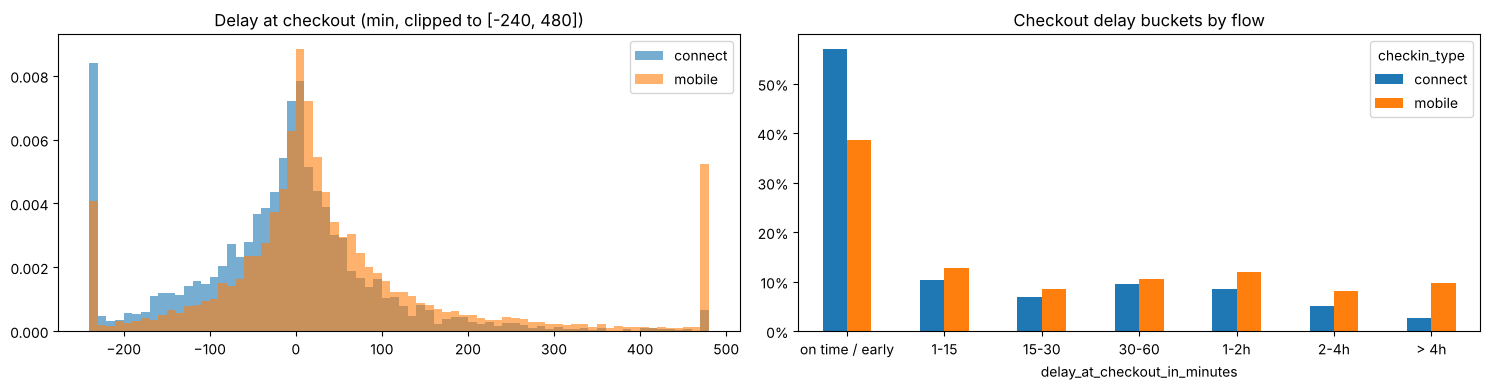

checkin_type,connect,mobile
delay_at_checkout_in_minutes,,
on time / early,0.571,0.386
1-15,0.103,0.127
15-30,0.068,0.085
30-60,0.096,0.106
1-2h,0.086,0.119
2-4h,0.051,0.081
> 4h,0.026,0.096


In [6]:
d = ended.dropna(subset=['delay_at_checkout_in_minutes'])
bins = [-1e9, 0, 15, 30, 60, 120, 240, 1e9]
labels = ['on time / early', '1-15', '15-30', '30-60', '1-2h', '2-4h', '> 4h']
dist = pd.crosstab(pd.cut(d['delay_at_checkout_in_minutes'], bins, labels=labels), d['checkin_type'], normalize='columns')
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for t, g in d.groupby('checkin_type'):
    ax[0].hist(g['delay_at_checkout_in_minutes'].clip(-240, 480), bins=72, alpha=0.6, label=t, density=True)
ax[0].set_title('Delay at checkout (min, clipped to [-240, 480])'); ax[0].legend()
dist.plot.bar(ax=ax[1], rot=0, title='Checkout delay buckets by flow'); ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()
dist.round(3)

**57% of the ended rentals (with a known checkout) are returned late**, but most delays are short: the median late driver is 53 minutes late. Connect drivers are late less often (43%) than mobile ones (61%).

## 2. Consecutive rentals and impact on the next driver

In [7]:
prev = raw[['rental_id', 'delay_at_checkout_in_minutes', 'checkin_type']].rename(columns={
    'rental_id': 'previous_ended_rental_id', 'delay_at_checkout_in_minutes': 'previous_delay', 'checkin_type': 'previous_checkin_type'})
df = raw.merge(prev, on='previous_ended_rental_id', how='left')
df['has_previous'] = df['time_delta_with_previous_rental_in_minutes'].notna()
df['is_problematic'] = df['has_previous'] & (df['previous_delay'] > df['time_delta_with_previous_rental_in_minutes'])
df['waiting_minutes'] = (df['previous_delay'] - df['time_delta_with_previous_rental_in_minutes']).clip(lower=0)
pairs = df[df['has_previous']]
print(f"Rentals with a previous rental < 12h before: {len(pairs)} ({len(pairs) / len(df):.1%})")
print(f"  of which previous delay known: {pairs['previous_delay'].notna().sum()}")
print(f"  previous driver late (delay > 0): {(pairs['previous_delay'] > 0).mean():.1%}")
prob = pairs[pairs['is_problematic']]
print(f"Problematic cases (previous delay > planned gap, next driver waits): {len(prob)} = {len(prob) / len(pairs):.1%} of consecutive rentals")
print(prob.groupby('checkin_type').size().rename('problematic cases').to_dict())

Rentals with a previous rental < 12h before: 1841 (8.6%)
  of which previous delay known: 1729
  previous driver late (delay > 0): 47.4%
Problematic cases (previous delay > planned gap, next driver waits): 218 = 11.8% of consecutive rentals
{'connect': 69, 'mobile': 149}


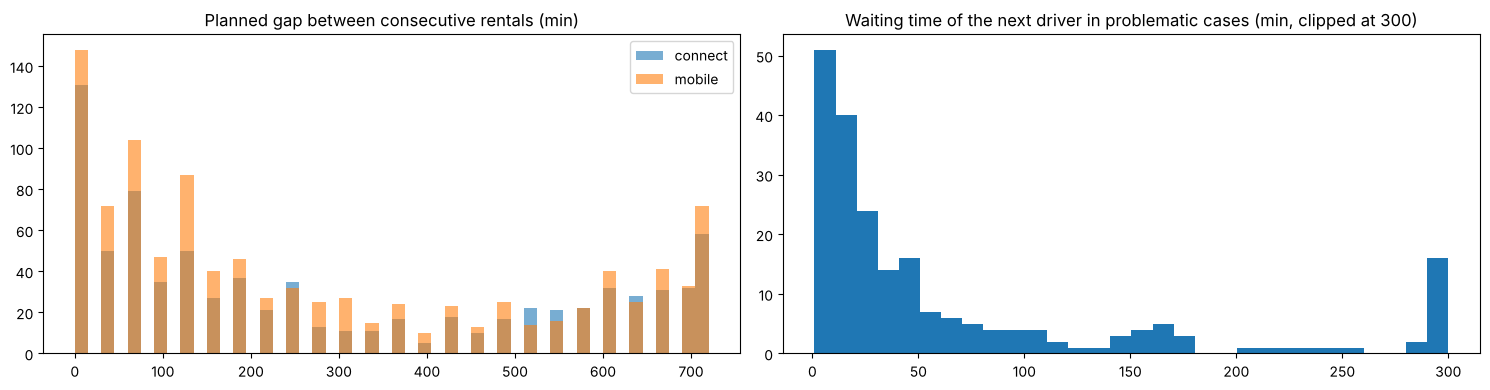

count      218.0
mean       178.0
std        925.0
min          1.0
25%         11.0
50%         26.0
75%         80.0
90%        214.0
max      12548.0
Name: waiting_minutes, dtype: float64

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for t, g in pairs.groupby('checkin_type'):
    ax[0].hist(g['time_delta_with_previous_rental_in_minutes'], bins=48, alpha=0.6, label=t)
ax[0].set_title('Planned gap between consecutive rentals (min)'); ax[0].legend()
ax[1].hist(prob['waiting_minutes'].clip(upper=300), bins=30)
ax[1].set_title('Waiting time of the next driver in problematic cases (min, clipped at 300)')
plt.tight_layout(); plt.show()
prob['waiting_minutes'].describe(percentiles=[.25, .5, .75, .9]).round(0)

In [9]:
known = pairs[pairs['previous_delay'].notna()]
cancel = known.groupby('is_problematic')['state'].apply(lambda s: (s == 'canceled').mean()).rename({False: 'not problematic', True: 'problematic'})
print('Cancellation rate of the next rental:'); print(cancel.round(3).to_string())
print(f"Overall cancellation rate: {(raw.state == 'canceled').mean():.3f}")

Cancellation rate of the next rental:
is_problematic
not problematic    0.112
problematic        0.170
Overall cancellation rate: 0.153


**Impact on the next driver:** 218 problematic cases (12% of consecutive rentals). The median wait is 26 minutes, but a quarter of these drivers wait more than 1h20. When the previous driver is late beyond the gap, the next rental is canceled 17% of the time, against 11% otherwise. This is a correlation (the dataset does not give the reason of a cancellation), but it supports the customer service feedback.

## 3. Simulation of the feature
Definitions:
- **Affected rental**: rental in scope whose planned gap with the previous rental is below the threshold: it could not be booked with these times.
- **Revenue potentially affected**: no price per rental in this dataset, so the proxy is the share of **ended** rentals that would be affected (equal average revenue per rental assumed). This is an upper bound: some drivers would book another slot or another car.
- **Solved case**: problematic case in scope, with a gap below the threshold and a previous delay not longer than the threshold (a gap of `threshold` minutes would have absorbed the delay).

In [10]:
SCOPES = {'All cars': ['mobile', 'connect'], 'Connect only': ['connect']}
n_ended = (df['state'] == 'ended').sum()

def simulate(threshold, scope):
    in_scope = df['checkin_type'].isin(SCOPES[scope])
    gap = df['time_delta_with_previous_rental_in_minutes']
    affected = in_scope & df['has_previous'] & (gap < threshold)
    solved = affected & df['is_problematic'] & (df['previous_delay'] <= threshold)
    return {'scope': scope, 'threshold': threshold, 'affected_rentals': int(affected.sum()),
            'revenue_affected_share': (affected & (df['state'] == 'ended')).sum() / n_ended,
            'problematic_in_scope': int((df['is_problematic'] & in_scope).sum()),
            'solved_cases': int(solved.sum()), 'solved_share_of_all_218': solved.sum() / df['is_problematic'].sum()}

sim = pd.DataFrame([simulate(t, s) for s in SCOPES for t in range(0, 721, 15)])
key = sim[sim['threshold'].isin([30, 60, 90, 120, 180, 240, 360])]
key.round(3)

,scope,threshold,affected_rentals,revenue_affected_share,problematic_in_scope,solved_cases,solved_share_of_all_218
2,All cars,30,279,0.014,218,68,0.312
4,All cars,60,401,0.020,218,102,0.468
6,All cars,90,584,0.029,218,132,0.606
8,All cars,120,666,0.033,218,147,0.674
12,All cars,180,870,0.043,218,167,0.766
16,All cars,240,1001,0.049,218,177,0.812
24,All cars,360,1170,0.057,218,193,0.885
51,Connect only,30,131,0.006,69,23,0.106
53,Connect only,60,181,0.009,69,36,0.165
55,Connect only,90,260,0.012,69,42,0.193


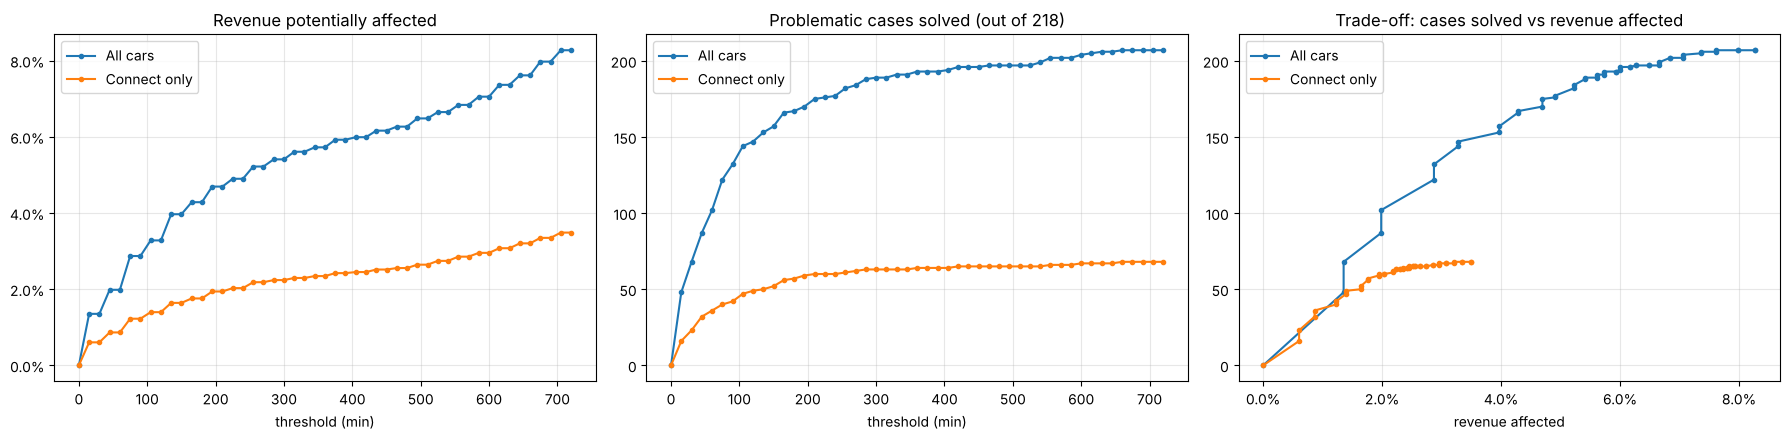

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for s, g in sim.groupby('scope'):
    ax[0].plot(g['threshold'], g['revenue_affected_share'], marker='.', label=s)
    ax[1].plot(g['threshold'], g['solved_cases'], marker='.', label=s)
    ax[2].plot(g['revenue_affected_share'], g['solved_cases'], marker='.', label=s)
ax[0].set_title('Revenue potentially affected'); ax[0].set_xlabel('threshold (min)'); ax[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax[1].set_title('Problematic cases solved (out of 218)'); ax[1].set_xlabel('threshold (min)')
ax[2].set_title('Trade-off: cases solved vs revenue affected'); ax[2].set_xlabel('revenue affected'); ax[2].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Answers and recommendation

| Question | Answer (data 2017) |
|---|---|
| Revenue potentially affected | grows with the threshold: ~2.0% of ended rentals at 60 min, ~3.3% at 120 min, ~4.9% at 240 min for all cars; less than half of that for Connect only (0.9% / 1.4% / 2.0%) |
| Rentals affected | all cars: 401 at 60 min, 666 at 120 min, 1,001 at 240 min; Connect only: 181 / 295 / 430 |
| How often drivers are late | 57% of ended rentals with a known checkout are returned late (Connect 43%, mobile 61%), median lateness 53 min; 12% of consecutive rentals become a problematic case (218); median wait 26 min |
| Problematic cases solved | all cars: 102 (47%) at 60 min, 147 (67%) at 120 min, 177 (81%) at 240 min; Connect only: 36 / 49 / 60, out of the 69 Connect cases |

**Reading the trade-off:**
- The marginal gain decreases fast: going from 0 to 120 min solves 2/3 of the problematic cases, the next 120 min solve only 14% more while blocking 50% more rentals.
- **Connect only** is the cheapest option (about 1% of revenue at 60-120 min) and Connect cars matter most: without an owner on site, nobody manages the wait. But it covers only 69 of the 218 problematic cases.
- Options for the Product Manager:
  - cautious launch: **Connect only, 60 to 120 min** (~1% of revenue, 52-71% of Connect cases solved);
  - broader impact: **all cars, 120 min** (~3.3% of revenue, 67% of all cases solved).

Limits: gaps are only known below 12h, revenue is a count proxy (no prices), and blocked rentals are not necessarily lost (drivers can shift their booking).